# ML-KEM-768 A측 CPA (비밀키 basemul)

수집한 전력 트레이스 `.npz`를 불러와, decapsulation의 첫 secret-key basemul
(`polyvec_basemul_acc_montgomery`, ŝ[0]·NTT(u[0]))에 CPA를 수행한다.

- 타깃 중간값: `montgomery_reduce(a1 · b1)` (PQClean `basemul`의 첫 `fqmul`)
  - `a1 = ŝ[VEC][2P+1]` : 비밀키 계수 (미지, 복구 대상), NTT 도메인, 0..q-1
  - `b1 = NTT(u)[VEC][2P+1]` : 암호문에서 나오는 알려진 값
- 누출 모델: 16비트 int16 결과의 Hamming weight
- 산출물: 정답 계수의 순위(PGE), 상관 vs 추측값, 상관 트레이스, 트레이스 수별 수렴

수집은 `mlkem-trace.ipynb`, 복호 포팅 검증은 `mlkem-test.ipynb` 참고.

## 1. PQClean clean 산술 포팅 (기기 중간값과 비트 단위 일치)

zetas·Montgomery·NTT를 `ml-kem-768/clean` 소스 그대로 옮긴 것. `b̂ = poly_ntt(Decompress(c1))`와 정답 `ŝ = poly_frombytes(dk)`가 kyber-py와 mod q로 일치함을 확인했다 (mlkem-test.ipynb).

In [1]:
import numpy as np                              # 수치 계산

Q, QINV, N, K = 3329, -3327, 256, 3               # q=모듈러스, QINV=q^-1 mod 2^16, N=계수수, K=다항식수(768)
ZETAS = [                                         # NTT twiddle 상수 128개 (ntt.c와 동일해야 b̂ 재현됨)
    -1044, -758, -359, -1517, 1493, 1422, 287, 202, -171, 622, 1577, 182, 962, -1202,
    -1474, 1468, 573, -1325, 264, 383, -829, 1458, -1602, -130, -681, 1017, 732, 608,
    -1542, 411, -205, -1571, 1223, 652, -552, 1015, -1293, 1491, -282, -1544, 516, -8,
    -320, -666, -1618, -1162, 126, 1469, -853, -90, -271, 830, 107, -1421, -247, -951,
    -398, 961, -1508, -725, 448, -1065, 677, -1275, -1103, 430, 555, 843, -1251, 871,
    1550, 105, 422, 587, 177, -235, -291, -460, 1574, 1653, -246, 778, 1159, -147, -777,
    1483, -602, 1119, -1590, 644, -872, 349, 418, 329, -156, -75, 817, 1097, 603, 610,
    1322, -1285, -1465, 384, -1215, -136, 1218, -1335, -874, 220, -1187, -1659, -1185,
    -1530, -1278, 794, -1510, -854, -870, 478, -108, -308, 996, 991, 958, -1460, 1522, 1628,
]

def to_i16(x):                                      # 값을 int16 범위로 wrap (보드가 int16_t라 똑같이 잘라야 함)
    return ((int(x) + 0x8000) & 0xFFFF) - 0x8000  # +2^15 후 2^16 마스크 후 -2^15 = 부호있는 16비트

def montgomery_reduce(a):                         # a * R^-1 mod q (R=2^16) — reduce.c와 비트 단위 동일
    t = to_i16(to_i16(a) * QINV)                      # t = (int16_t)((int16_t)a * QINV)
    return (int(a) - t * Q) >> 16                 # (a - t*q) >> 16 (산술 시프트)

def fqmul(a, b):                                  # NTT 도메인 곱 = mont(a*b)
    return montgomery_reduce(to_i16(a) * to_i16(b))   # 두 int16을 곱해 몽고메리 리덕션

def barrett_reduce(a):                            # poly_reduce: ntt 뒤 보드가 적용하는 reduce (대표값 맞춤)
    v = ((1 << 26) + Q // 2) // Q                 # barrett 상수 round(2^26 / q)
    t = (v * to_i16(a) + (1 << 25)) >> 26           # t = round(a / q)
    return to_i16(to_i16(a) - to_i16(t * Q))            # a - t*q (centered 대표값)

def ntt(r):                                       # 정방향 NTT (normal -> bitreversed order)
    r = [to_i16(x) for x in r]                      # 입력을 int16로 (보드와 동일 표현)
    k, length = 1, 128                            # k=zeta 인덱스, length=butterfly 거리
    while length >= 2:                            # 길이 128,64,...,2 로 7단
        start = 0                                 # 각 단의 그룹 시작 위치
        while start < 256:                        # 256계수를 그룹 단위로 훑음
            zeta = ZETAS[k]; k += 1               # 이 그룹의 twiddle
            for j in range(start, start + length):# 그룹 내 butterfly
                t = fqmul(zeta, r[j + length])    # 짝 계수에 twiddle 곱
                r[j + length] = to_i16(r[j] - t)    # 아래쪽 = 위 - t
                r[j] = to_i16(r[j] + t)             # 위쪽 = 위 + t
            start = j + length + 1                # 다음 그룹 시작 (start + 2*length)
        length >>= 1                              # 다음 단은 거리 절반
    return r                                       # NTT 결과 리스트 반환

def poly_frombytes(a):                            # dk의 12비트 패킹을 NTT 비밀키 계수로 복원 (0..q-1)
    r = [0] * N                                   # 256계수 버퍼
    for i in range(N // 2):                       # 3바이트가 2계수
        r[2*i]   = ((a[3*i] >> 0) | (a[3*i+1] << 8)) & 0xFFF   # 하위 12비트 = 계수 0
        r[2*i+1] = ((a[3*i+1] >> 4) | (a[3*i+2] << 4)) & 0xFFF # 상위 12비트 = 계수 1
    return r                                       # ŝ 한 다항식

def polyvec_decompress_vec(a):                    # c1 압축(du=10) 해제: 320바이트 -> 256 normal 계수
    r = [0] * N; p = 0                            # r=출력, p=바이트 포인터
    for j in range(N // 4):                       # 5바이트가 4계수(10비트×4)
        t = ((a[p] | a[p+1] << 8),                # 10비트 값 4개 추출
             (a[p+1] >> 2 | a[p+2] << 6),
             (a[p+2] >> 4 | a[p+3] << 4),
             (a[p+3] >> 6 | a[p+4] << 2))
        p += 5                                    # 다음 5바이트로
        for kk in range(4):                       # 4계수 각각 Decompress
            r[4*j+kk] = ((t[kk] & 0x3FF) * Q + 512) >> 10   # round(q/2^10 * t)
    return r                                       # u 한 다항식 (normal 도메인)

def bhat_from_ct(ct):                             # 아는 값 b̂ = poly_ntt(Decompress(c1)) — 보드 poly_ntt와 동일
    out = []                                      # 다항식 K개
    for i in range(K):                            # 각 u 벡터 성분
        coeffs = polyvec_decompress_vec(ct[320*i:320*(i+1)])  # c1의 i번째 320바이트 -> u_i
        coeffs = ntt(coeffs)                      # 정방향 NTT (반환값 사용)
        out.append([barrett_reduce(x) for x in coeffs])       # ntt 뒤 poly_reduce 적용
    return out                                     # b̂ (NTT 도메인)

def shat_from_dk(dk):                             # 정답 비밀키 ŝ (채점용) — dk 앞 384*K 바이트
    return [poly_frombytes(dk[384*i:384*(i+1)]) for i in range(K)]  # 다항식 K개

print("port loaded")                              # 로드 확인

port loaded


## 2. 트레이스 `.npz` 불러오기

`mlkem-trace.ipynb`가 저장한 파일(`traces`, `ct`, `ss`, `dk`, `ek`). TVLA 파일은 제외한다.

In [ ]:
import glob                                     # 파일 패턴 검색

cand = [p for p in glob.glob("../traces/mlkem*-*.npz") if "tvla" not in p]  # 수집 파일만 (tvla 제외)
path = sorted(cand)[-1]                           # 이름순 가장 마지막(=최근) 파일; 직접 지정도 가능
print("loading:", path)                           # 어떤 파일 쓰는지 표시

with np.load(path) as d:                          # with: 읽고 파일 핸들 닫음(윈도우 잠금 방지)
    traces = d["traces"].astype(np.float32)       # (T, S) 파형
    cts    = d["ct"]                              # (T, 1088) 암호문 — traces[i] <-> cts[i] 정렬
    dk     = d["dk"].tobytes()                    # 비밀키 bytes (채점용)
    if "impl" in d.files:                         # 수집 노트북이 저장한 메타가 있으면
        print("meta -> scheme:", int(d["scheme"]), " impl:", str(d["impl"]),  # 스킴/구현/최적화/캡처 확인
              " opt: -O" + str(d["opt"]), " samples:", int(d["samples"]))

T, S = traces.shape                               # T=파형 수, S=샘플 수
print("traces:", traces.shape, " ct:", cts.shape) # 모양 확인

## 3. 공격 타깃 설정

`VEC`번째 비밀키 다항식, 계수쌍 `P`의 홀수 계수 `a1 = ŝ[VEC][2P+1]`을 복구한다. A 타깃(첫 basemul)은 `VEC=0`. 알려진 값 `b1`은 파형마다 암호문에서 계산한다.

In [3]:
VEC, P = 0, 7                                     # 타깃 좌표: a1 = ŝ[VEC][2P+1] (0<=P<128, A타깃은 VEC=0)

true_a1 = shat_from_dk(dk)[VEC][2*P + 1]          # 채점용 정답 계수 (rank 매길 때만 사용)
# b1[t] = b̂[VEC][2P+1] : 파형 t의 "아는 값"을 암호문에서 보드와 동일하게 재현
b1 = np.array([bhat_from_ct(bytes(ct))[VEC][2*P + 1] for ct in cts], dtype=np.int64)  # 파형마다 1개
print("true a1 =", true_a1, " | b1[:5] =", b1[:5])  # 정답과 b1 앞부분 확인

true a1 = 3293  | b1[:5] = [ -882    93  1591 -1374   379]


## 4. CPA

추측 `g=0..q-1`마다 모델 `HW16(montgomery_reduce(g·b1))`을 만들고, 각 샘플과 Pearson 상관 →
샘플축 최대 |상관|을 그 추측의 점수로 삼는다. 점수 1등이 복구값.

**주의 — a0/a1 ghost:** basemul은 `b1`을 두 번 곱한다.
`r[0]=fqmul(a1,b1)` (우리 타깃)과 `r[1]=fqmul(a0,b1)`. 모델 `HW(mont(g·b1))`은 둘 다에 반응해서,
전체 구간이면 더 세게 새는 쪽(보통 짝수 계수 a0)이 ghost로 1등을 뺏는다. 두 연산은 **다른 샘플**에서
새므로, 셀 5 상관 트레이스에서 a1 피크 위치를 보고 `WINDOW`를 그 구간으로 좁히면 a1이 1등이 된다.

In [14]:
WINDOW = (3800, 3850)                                     # None=전체 샘플, (lo,hi)=그 구간만 (a0 ghost 분리용). 예: (3790, 3860)

HW16_TABLE = np.array([bin(v).count("1") for v in range(1 << 16)], dtype=np.uint8)  # 0..65535의 비트1 개수 표

def montgomery_reduce_vec(x):                     # 벡터화 montgomery_reduce (reduce.c와 비트 단위 동일)
    x  = x.astype(np.int64)                        # x = guess*b1 (오버플로 방지 int64)
    lo = x.astype(np.int16)                        # (int16_t)x
    t  = (lo.astype(np.int32) * QINV).astype(np.int16)        # t = (int16_t)(lo*QINV)
    return ((x - t.astype(np.int64) * Q) >> 16).astype(np.int16)  # (x - t*q)>>16

key_guesses = np.arange(Q)                        # 추측 0..3328 (전수)
guess_x_b1  = key_guesses[:, None].astype(np.int64) * b1[None, :]  # (추측 × 트레이스) 모든 곱
hw_model    = HW16_TABLE[montgomery_reduce_vec(guess_x_b1).astype(np.uint16)].astype(np.float64)  # 예측 HW
model_centered = hw_model - hw_model.mean(axis=1, keepdims=True)   # 추측별 평균 제거(상관 분자용)
model_norm     = np.sqrt((model_centered ** 2).sum(axis=1)) + 1e-12  # 추측별 norm (+eps: guess=0 상수 방지)

lo, hi = (0, S) if WINDOW is None else WINDOW     # 분석할 샘플 구간
win = traces[:, lo:hi].astype(np.float64)         # 그 구간 파형만 슬라이스
win_centered = win - win.mean(axis=0)             # 샘플별 평균 제거
win_norm     = np.sqrt((win_centered ** 2).sum(axis=0)) + 1e-12   # 샘플별 norm
corr = (model_centered @ win_centered) / (model_norm[:, None] * win_norm[None, :])  # (추측 × 샘플) Pearson

abs_corr              = np.abs(corr)              # 부호 무시(+/- 누출 둘 다)
best_corr_per_guess   = abs_corr.max(axis=1)      # 추측별 점수 = 샘플축 최대 |상관|
peak_sample_per_guess = abs_corr.argmax(axis=1) + lo  # 그 최대가 난 샘플(전체 파형 기준 보정)

ranked_guesses = np.argsort(best_corr_per_guess)[::-1]           # 점수 높은 순 추측 정렬
true_rank      = int(np.where(ranked_guesses == true_a1)[0][0])  # 정답 등수 (0=1등=복구)
recovered_a1   = int(ranked_guesses[0])           # CPA가 고른 키(1등)
print(f"window = {(lo, hi)}")                     # 분석 구간
print(f"recovered a1 = {recovered_a1}   true a1 = {true_a1}   rank(0=best) = {true_rank}")  # 결과
print("top5 (guess, score, peak_sample):")        # 상위 5개 진단(ghost 위치 확인용)
for g in ranked_guesses[:5]:                      # 점수 상위 5 추측
    tag = "  <= TRUE" if g == true_a1 else ""     # 정답 표시
    print(f"  g={int(g):4d}  score={best_corr_per_guess[g]:.4f}  @sample {int(peak_sample_per_guess[g])}{tag}")

window = (3800, 3850)
recovered a1 = 3293   true a1 = 3293   rank(0=best) = 0
top5 (guess, score, peak_sample):
  g=3293  score=0.8810  @sample 3828  <= TRUE
  g=  36  score=0.8387  @sample 3840
  g=1044  score=0.3462  @sample 3804
  g=2285  score=0.3247  @sample 3804
  g=  12  score=0.3161  @sample 3840


## 5. 그래프: 상관 vs 추측값, 상관 트레이스

상관 트레이스는 **전체 구간**으로 그린다 — a1 피크와 a0 ghost 피크가 다른 샘플에 보이므로, 여기서 a1 피크 위치를 읽어 셀 4의 `WINDOW`를 정한다.

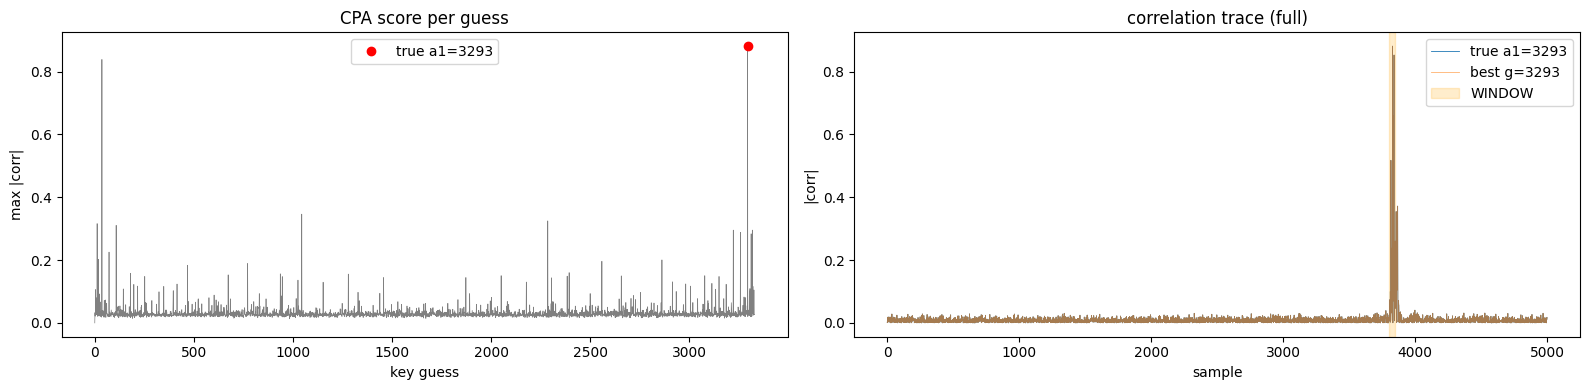

In [15]:
import matplotlib.pyplot as plt                 # 그래프

full_centered = traces.astype(np.float64) - traces.astype(np.float64).mean(axis=0)  # 전체 파형 평균 제거
full_norm     = np.sqrt((full_centered ** 2).sum(axis=0)) + 1e-12   # 샘플별 norm
corr_true = np.abs((model_centered[true_a1]      @ full_centered) / (model_norm[true_a1]      * full_norm))  # 정답 추측 상관트레이스
corr_best = np.abs((model_centered[recovered_a1] @ full_centered) / (model_norm[recovered_a1] * full_norm))  # 1등 추측 상관트레이스

fig, ax = plt.subplots(1, 2, figsize=(16, 4))     # 1행 2열

ax[0].plot(best_corr_per_guess, lw=0.5, color="gray")                       # 추측별 점수 전체
ax[0].plot(true_a1, best_corr_per_guess[true_a1], "ro", label=f"true a1={true_a1}")  # 정답 위치 강조
ax[0].set_xlabel("key guess"); ax[0].set_ylabel("max |corr|")              # 축 라벨
ax[0].set_title("CPA score per guess"); ax[0].legend()                     # 제목/범례

ax[1].plot(corr_true, lw=0.6, label=f"true a1={true_a1}")                   # 정답 추측 누출 위치
ax[1].plot(corr_best, lw=0.6, alpha=0.6, label=f"best g={recovered_a1}")    # 1등 추측 누출 위치(ghost면 다른 샘플)
if WINDOW is not None:                                                      # 윈도우 지정 시
    ax[1].axvspan(WINDOW[0], WINDOW[1], color="orange", alpha=0.2, label="WINDOW")  # 구간 음영
ax[1].set_xlabel("sample"); ax[1].set_ylabel("|corr|")                     # 축 라벨
ax[1].set_title("correlation trace (full)"); ax[1].legend()                # 제목/범례

plt.tight_layout(); plt.show()                                             # 배치/표시

## 6. 트레이스 수별 수렴 (정답 계수의 순위)

셀 4의 `WINDOW` 안에서, 트레이스를 늘리며 정답 계수의 rank가 0으로 떨어지는지 본다. A측 CPA feasibility의 정량 근거.

N=     2  rank=157
N=     3  rank=1336
N=     4  rank=1048
N=     5  rank=513
N=     6  rank=72
N=     7  rank=12
N=     8  rank=0
N=     9  rank=41
N=    10  rank=10
N=    11  rank=2
N=    12  rank=0
N=    13  rank=0
N=    14  rank=0
N=    15  rank=2
N=    16  rank=2
N=    17  rank=0
N=    18  rank=0
N=    19  rank=0
N=    20  rank=0
N=    21  rank=0
N=    22  rank=0
N=    23  rank=0
N=    24  rank=0
N=    25  rank=0
N=    26  rank=0
N=    27  rank=0
N=    28  rank=0
N=    29  rank=0
N=    30  rank=0
N=    31  rank=0
N=    32  rank=1
N=    33  rank=1
N=    34  rank=1
N=    35  rank=1
N=    36  rank=1
N=    37  rank=1
N=    38  rank=1
N=    39  rank=1
N=    40  rank=1
N=    41  rank=1
N=    42  rank=1
N=    43  rank=1
N=    44  rank=1
N=    45  rank=1
N=    46  rank=1
N=    47  rank=1
N=    48  rank=1
N=    49  rank=1
N=    50  rank=1
N=    51  rank=1
N=    52  rank=1
N=    53  rank=1
N=    54  rank=1
N=    55  rank=1
N=    56  rank=1
N=    57  rank=1
N=    58  rank=1
N=    59  rank=1


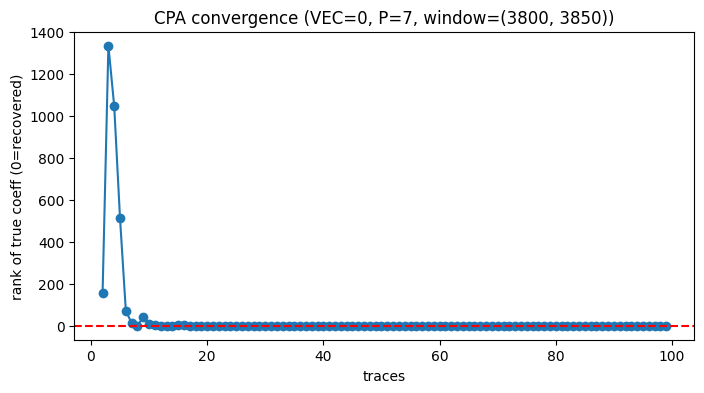

In [16]:
steps = [i for i in range(2, 100)]  # 늘려볼 트레이스 수
rank_curve = []                                   # 각 n의 rank 기록

for n in steps:                                   # 트레이스 n개만으로 반복
    model_n          = hw_model[:, :n]            # 앞 n개 트레이스의 모델
    model_n_centered = model_n - model_n.mean(axis=1, keepdims=True)       # 평균 제거
    model_n_norm     = np.sqrt((model_n_centered ** 2).sum(axis=1)) + 1e-12  # norm

    win_n          = traces[:n, lo:hi].astype(np.float64)                  # 앞 n개 × 셀4 WINDOW 구간
    win_n_centered = win_n - win_n.mean(axis=0)                            # 평균 제거
    win_n_norm     = np.sqrt((win_n_centered ** 2).sum(axis=0)) + 1e-12    # norm

    corr_n  = (model_n_centered @ win_n_centered) / (model_n_norm[:, None] * win_n_norm[None, :])  # 상관
    score_n = np.abs(corr_n).max(axis=1)          # 추측별 점수
    rank_n  = int((score_n > score_n[true_a1]).sum())  # 정답보다 높은 추측 수(0=복구)
    rank_curve.append(rank_n)                     # 기록
    print(f"N={n:6d}  rank={rank_n}")             # 진행 표시

plt.figure(figsize=(8, 4))                        # 새 그림
plt.plot(steps, rank_curve, "o-")                 # 트레이스 수 vs rank
plt.axhline(0, color="r", ls="--")                # rank 0 기준선
plt.xlabel("traces"); plt.ylabel("rank of true coeff (0=recovered)")  # 축 라벨
plt.title(f"CPA convergence (VEC={VEC}, P={P}, window={(lo, hi)})"); plt.show()  # 제목/표시